# 🛒 PROYEK AKHIR PRAKTIKUM DATA SCIENCE 2026/2027
# Segmentasi Profil dan Perilaku Pelanggan Ritel Berdasarkan Pendapatan dan Riwayat Transaksi Belanja Menggunakan Metode Clustering

---

**TIM PENYUSUN — PRODI INFORMATIKA UPN "VETERAN" YOGYAKARTA:**
1. **Grahito Ardianto Purnomo** (123240001)
2. **Fahri Hidayatullah** (123240002)
3. **Krocasadigandra Arzaq Kubro M.** (123240015)
4. **Gian Abi Firdaus** (123240017)

**DATASET:** Customer Personality Analysis (`marketing_campaign.csv` — Kaggle)

---

### Alur Pengerjaan Notebook (Sesuai Panduan Proyek Akhir)
Notebook ini disusun secara lengkap dan berurutan mengikuti 7 tahapan utama yang ditetapkan pada Panduan Proyek Akhir Praktikum Data Science:
1. **Tahap A — Business Understanding**: Latar belakang masalah, pertanyaan bisnis, metode clustering, serta metrik evaluasi.
2. **Tahap B — Data Gathering**: Pemuatan data, sumber & tautan dataset, alasan pemilihan, serta kamus data 29 kolom.
3. **Tahap C — Exploratory Data Analysis (EDA)**: Statistik deskriptif dan visualisasi data disertai penjelasan temuan di bawah setiap grafik.
4. **Tahap D — Cleaning, Preprocessing, dan Feature Selection**: Audit kualitas data, pembersihan data (komparasi sebelum vs sesudah), rekayasa fitur, seleksi fitur, *log-transform*, *scaling*, *train-test split*, dan PCA.
5. **Tahap E — Modelling**: Pembuatan model utama (**K-Means**) serta dua model pembanding (**Agglomerative Hierarchical Clustering** dan **DBSCAN**) dengan alasan pada setiap langkah kode.
6. **Tahap F — Evaluasi**: Perbandingan metrik penilaian, grafik pendukung, uji generalisasi (Train vs Test), pemilihan model terbaik, serta *profiling* segmen pelanggan.
7. **Tahap G — Konklusi**: Jawaban atas pertanyaan bisnis, terjemahan metrik ke bahasa bisnis, rekomendasi strategis per segmen, dan keterbatasan proyek.

## 0. Setup Lingkungan & Import Library

Pada langkah awal ini, seluruh pustaka komputasi numerik (`numpy`, `pandas`), visualisasi (`matplotlib`, `seaborn`), dan pemodelan *machine learning* (`scikit-learn`, `scipy`) dimuat. Nilai `RANDOM_STATE = 42` dikunci agar hasil pembagian data, reduksi dimensi PCA, dan inisialisasi centroid K-Means bersifat reproduktibel setiap kali notebook dijalankan ulang.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Konfigurasi tampilan grafik dan tabel pandas
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RANDOM_STATE = 42
DATA_PATH = "marketing_campaign.csv"
REF_YEAR = 2014  # Tahun referensi terakhir pencatatan dataset

print("Lingkungan eksekusi berhasil disiapkan:")
print(f" - Pandas       : {pd.__version__}")
print(f" - NumPy        : {np.__version__}")
print(f" - Random State : {RANDOM_STATE}")

Lingkungan eksekusi berhasil disiapkan:
 - Pandas       : 2.0.0
 - NumPy        : 1.26.3
 - Random State : 42


---
# TAHAP A: BUSINESS UNDERSTANDING

## A.1 Latar Belakang & Rumusan Masalah
Dalam industri ritel modern, pendekatan promosi massal (*mass marketing*) yang mengirimkan penawaran seragam kepada seluruh pelanggan sering kali tidak efisien dan memboroskan anggaran pemasaran. Hal ini tercermin pada data historis kampanye pemasaran perusahaan ritel, di mana tingkat penerimaan (*acceptance rate*) kampanye ke-1 hingga ke-5 sangat rendah (hanya berkisar antara 1,3% hingga 7,5%).

Penyebab utama inefisiensi tersebut adalah keragaman (*heterogeneity*) pelanggan: pelanggan dengan pendapatan tinggi tanpa tanggungan anak memiliki pola konsumsi produk dan preferensi kanal transaksi yang sangat berbeda dibandingkan keluarga berpenghasilan menengah atau pelanggan hemat pencari diskon. Oleh karena itu, perusahaan membutuhkan **segmentasi pelanggan berbasis data** untuk mengelompokkan pelanggan ke dalam beberapa segmen homogen agar strategi promosi, penawaran produk, dan kanal komunikasi dapat disesuaikan secara tepat sasaran.

## A.2 Pertanyaan yang Ingin Dijawab
1. **Bagaimana pola distribusi pendapatan, pengeluaran produk, komposisi keluarga, dan perilaku kanal belanja pelanggan ritel pada dataset ini?**
2. **Berapa jumlah segmen (*cluster*) pelanggan yang paling optimal secara matematis sekaligus paling mudah diinterpretasikan untuk kebutuhan bisnis?**
3. **Di antara algoritma *clustering* yang dipelajari pada praktikum (K-Means, Agglomerative Hierarchical Clustering, dan DBSCAN), model manakah yang menghasilkan kualitas segmentasi terbaik?**
4. **Bagaimana karakteristik profil masing-masing segmen pelanggan yang terbentuk, dan keputusan strategi bisnis apa yang sebaiknya diambil untuk setiap segmen?**

## A.3 Metode yang Digunakan
Karena dataset tidak memiliki label segmen pelanggan yang telah ditentukan sebelumnya (*unlabeled*), pendekatan yang digunakan adalah **Unsupervised Learning — Clustering**. Untuk menjamin objektivitas pemilihan model, proyek ini membandingkan **3 algoritma clustering dari materi praktikum**:
1. **K-Means Clustering**: Algoritma berbasis partisi centroid yang efisien untuk data numerik terstandarisasi dan mampu menetapkan segmen pelanggan baru secara langsung.
2. **Agglomerative Hierarchical Clustering (Ward Linkage)**: Algoritma berbasis hierarki *bottom-up* yang tidak memerlukan inisialisasi acak dan dapat divisualisasikan melalui dendrogram.
3. **DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*)**: Algoritma berbasis kerapatan (*density*) yang mampu menemukan cluster berbentuk non-sferis sekaligus mendeteksi titik *noise*/pencilan.

## A.4 Metrik Penilaian yang Digunakan
Kualitas hasil *clustering* dievaluasi secara kuantitatif menggunakan empat metrik utama:
- **Inertia / Within-Cluster Sum of Squares (Elbow Method)**: Mengukur total jarak kuadrat tiap data ke centroid cluster-nya; digunakan untuk melihat titik siku (*elbow*) jumlah cluster optimal pada K-Means.
- **Silhouette Score** (rentang $-1$ hingga $+1$, target proyek $\ge 0,30$): Mengukur seberapa dekat suatu data dengan anggota cluster-nya sendiri (*cohesion*) dibandingkan dengan cluster terdekat lainnya (*separation*). Semakin mendekati $+1$, semakin baik pemisahan cluster.
- **Davies-Bouldin Index / DBI** (rentang $\ge 0$, target proyek $< 1,50$): Mengukur rata-rata rasio kesamaan antara setiap cluster dengan cluster yang paling mirip dengannya. **Semakin rendah nilai DBI, semakin baik** pemisahan antar-cluster.
- **Calinski-Harabasz Index / CHI** (rentang $\ge 0$): Mengukur rasio dispersi antar-cluster terhadap dispersi di dalam cluster. **Semakin tinggi nilai CHI, semakin padat dan terpisah** cluster yang terbentuk.
- **Validasi Generalisasi (Train vs Test)** & **Validasi Eksternal (`Response`)**: Memastikan kestabilan metrik pada data uji (20% Test Set) serta memeriksa apakah segmen yang terbentuk berkorelasi nyata dengan tingkat respons kampanye terakhir (`Response`).

---
# TAHAP B: DATA GATHERING

## B.1 Sumber, Tautan, dan Kredibilitas Dataset
- **Nama Dataset**: *Customer Personality Analysis* (`marketing_campaign.csv`)
- **Sumber & Tautan**: Kaggle — [https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)
- **Penyedia Asli**: Dr. Omar Romero-Hernandez (diunggah oleh akun `imakash3011`).
- **Lisensi**: **Creative Commons Public Domain (CC0 1.0)** — bebas digunakan untuk riset akademik maupun komersial.
- **Privasi Data**: Dataset sepenuhnya teranonimkan tanpa informasi identitas pribadi (tidak ada nama, alamat, email, atau nomor telepon; hanya pengenal numerik `ID`).

## B.2 Pengertian Dataset & Alasan Pemilihan
Dataset *Customer Personality Analysis* berisi catatan profil demografi, komposisi rumah tangga, riwayat pengeluaran pada 6 kategori produk selama 2 tahun terakhir, preferensi kanal pembelian (toko fisik, web, katalog, diskon), serta riwayat respons terhadap kampanye promosi dari pelanggan sebuah perusahaan ritel.

**Alasan memilih dataset ini:**
1. **Memenuhi seluruh syarat teknis proyek akhir**: Memiliki 2.240 baris dan 29 kolom (jauh melampaui syarat minimal 100 baris dan 4 fitur).
2. **Memiliki karakteristik data kotor yang realistis**: Terdapat *missing value* pada `Income`, duplikat profil pelanggan, outlier ekstrem (tahun lahir $\le 1900$ dan pendapatan `666.666`), kategori tidak standar, serta kolom konstan—sangat ideal untuk mempraktikkan tahap *Cleaning* dan *Preprocessing* secara menyeluruh.
3. **Kaya konteks bisnis**: Memungkinkan penggabungan analisis statistik dengan *profiling* pemasaran nyata (daya beli, sensitivitas diskon, dan tingkat respons kampanye).

In [2]:
# Memuat dataset mentah (delimiter berupa karakter Tab '\t')
df_raw = pd.read_csv(DATA_PATH, sep="\t")

print(f"Dimensi dataset mentah : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")

tgl_raw = pd.to_datetime(df_raw["Dt_Customer"], format="%d-%m-%Y")
print(f"Rentang registrasi     : {tgl_raw.min().strftime('%d %B %Y')} s.d. {tgl_raw.max().strftime('%d %B %Y')}")
print("\n5 Baris Pertama Dataset Mentah:")
display(df_raw.head())

Dimensi dataset mentah : 2,240 baris x 29 kolom
Rentang registrasi     : 30 July 2012 s.d. 29 June 2014

5 Baris Pertama Dataset Mentah:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,"58,138.00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,"46,344.00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,"71,613.00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,"26,646.00",1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,"58,293.00",1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## B.3 Kamus Data (Arti Setiap Kolom dalam 4 Dimensi)
Seluruh 29 kolom pada dataset dikelompokkan ke dalam 4 dimensi utama agar mudah dipahami konteks bisnisnya:
1. **People (Kolom 1–7)**: Identitas, demografi, komposisi keluarga, dan pendapatan tahunan rumah tangga.
2. **Waktu & Products (Kolom 8–15)**: Tanggal registrasi, kebaruan transaksi (*Recency*), dan total belanja 2 tahun pada 6 kategori produk.
3. **Place & Promotion (Kolom 16–22)**: Kanal pembelian, frekuensi pembelian diskon, kunjungan web bulanan, serta respons kampanye awal.
4. **Promotion & Administratif (Kolom 23–29)**: Respons kampanye lanjutan, status keluhan (*Complain*), serta kolom konstan administratif.

In [3]:
# Membuat tabel kamus data untuk seluruh 29 kolom dataset
dict_data = [
    (1, "ID", "People", "Pengenal unik pelanggan", str(df_raw["ID"].dtype), df_raw["ID"].iloc[0]),
    (2, "Year_Birth", "People", "Tahun kelahiran pelanggan", str(df_raw["Year_Birth"].dtype), df_raw["Year_Birth"].iloc[0]),
    (3, "Education", "People", "Tingkat pendidikan pelanggan", str(df_raw["Education"].dtype), df_raw["Education"].iloc[0]),
    (4, "Marital_Status", "People", "Status pernikahan pelanggan", str(df_raw["Marital_Status"].dtype), df_raw["Marital_Status"].iloc[0]),
    (5, "Income", "People", "Pendapatan tahunan rumah tangga", str(df_raw["Income"].dtype), df_raw["Income"].iloc[0]),
    (6, "Kidhome", "People", "Jumlah anak kecil di rumah tangga", str(df_raw["Kidhome"].dtype), df_raw["Kidhome"].iloc[0]),
    (7, "Teenhome", "People", "Jumlah remaja di rumah tangga", str(df_raw["Teenhome"].dtype), df_raw["Teenhome"].iloc[0]),
    (8, "Dt_Customer", "Waktu", "Tanggal pendaftaran pelanggan (dd-mm-yyyy)", str(df_raw["Dt_Customer"].dtype), df_raw["Dt_Customer"].iloc[0]),
    (9, "Recency", "Waktu", "Jumlah hari sejak transaksi terakhir", str(df_raw["Recency"].dtype), df_raw["Recency"].iloc[0]),
    (10, "MntWines", "Products", "Pengeluaran produk wine (2 tahun terakhir)", str(df_raw["MntWines"].dtype), df_raw["MntWines"].iloc[0]),
    (11, "MntFruits", "Products", "Pengeluaran produk buah (2 tahun terakhir)", str(df_raw["MntFruits"].dtype), df_raw["MntFruits"].iloc[0]),
    (12, "MntMeatProducts", "Products", "Pengeluaran produk daging (2 tahun terakhir)", str(df_raw["MntMeatProducts"].dtype), df_raw["MntMeatProducts"].iloc[0]),
    (13, "MntFishProducts", "Products", "Pengeluaran produk ikan (2 tahun terakhir)", str(df_raw["MntFishProducts"].dtype), df_raw["MntFishProducts"].iloc[0]),
    (14, "MntSweetProducts", "Products", "Pengeluaran makanan manis (2 tahun terakhir)", str(df_raw["MntSweetProducts"].dtype), df_raw["MntSweetProducts"].iloc[0]),
    (15, "MntGoldProds", "Products", "Pengeluaran produk emas/premium (2 tahun terakhir)", str(df_raw["MntGoldProds"].dtype), df_raw["MntGoldProds"].iloc[0]),
    (16, "NumDealsPurchases", "Place & Promo", "Jumlah pembelian menggunakan diskon", str(df_raw["NumDealsPurchases"].dtype), df_raw["NumDealsPurchases"].iloc[0]),
    (17, "NumWebPurchases", "Place & Promo", "Jumlah pembelian melalui situs web", str(df_raw["NumWebPurchases"].dtype), df_raw["NumWebPurchases"].iloc[0]),
    (18, "NumCatalogPurchases", "Place & Promo", "Jumlah pembelian melalui katalog", str(df_raw["NumCatalogPurchases"].dtype), df_raw["NumCatalogPurchases"].iloc[0]),
    (19, "NumStorePurchases", "Place & Promo", "Jumlah pembelian langsung di toko fisik", str(df_raw["NumStorePurchases"].dtype), df_raw["NumStorePurchases"].iloc[0]),
    (20, "NumWebVisitsMonth", "Place & Promo", "Frekuensi kunjungan situs web per bulan", str(df_raw["NumWebVisitsMonth"].dtype), df_raw["NumWebVisitsMonth"].iloc[0]),
    (21, "AcceptedCmp3", "Promotion", "1 jika menerima kampanye ke-3, 0 jika tidak", str(df_raw["AcceptedCmp3"].dtype), df_raw["AcceptedCmp3"].iloc[0]),
    (22, "AcceptedCmp4", "Promotion", "1 jika menerima kampanye ke-4, 0 jika tidak", str(df_raw["AcceptedCmp4"].dtype), df_raw["AcceptedCmp4"].iloc[0]),
    (23, "AcceptedCmp5", "Promotion", "1 jika menerima kampanye ke-5, 0 jika tidak", str(df_raw["AcceptedCmp5"].dtype), df_raw["AcceptedCmp5"].iloc[0]),
    (24, "AcceptedCmp1", "Promotion", "1 jika menerima kampanye ke-1, 0 jika tidak", str(df_raw["AcceptedCmp1"].dtype), df_raw["AcceptedCmp1"].iloc[0]),
    (25, "AcceptedCmp2", "Promotion", "1 jika menerima kampanye ke-2, 0 jika tidak", str(df_raw["AcceptedCmp2"].dtype), df_raw["AcceptedCmp2"].iloc[0]),
    (26, "Complain", "Promotion", "1 jika mengajukan komplain dalam 2 tahun, 0 jika tidak", str(df_raw["Complain"].dtype), df_raw["Complain"].iloc[0]),
    (27, "Z_CostContact", "Administratif", "Kolom administratif bernilai konstan (3)", str(df_raw["Z_CostContact"].dtype), df_raw["Z_CostContact"].iloc[0]),
    (28, "Z_Revenue", "Administratif", "Kolom administratif bernilai konstan (11)", str(df_raw["Z_Revenue"].dtype), df_raw["Z_Revenue"].iloc[0]),
    (29, "Response", "Promotion", "1 jika menerima kampanye terakhir, 0 jika tidak", str(df_raw["Response"].dtype), df_raw["Response"].iloc[0]),
]

df_dict = pd.DataFrame(dict_data, columns=["No", "Nama Kolom", "Dimensi", "Deskripsi", "Tipe Data", "Contoh Nilai"])
display(df_dict)

,No,Nama Kolom,Dimensi,Deskripsi,Tipe Data,Contoh Nilai
0,1,ID,People,Pengenal unik pelanggan,int64,5524
1,2,Year_Birth,People,Tahun kelahiran pelanggan,int64,1957
2,3,Education,People,Tingkat pendidikan pelanggan,object,Graduation
3,4,Marital_Status,People,Status pernikahan pelanggan,object,Single
4,5,Income,People,Pendapatan tahunan rumah tangga,float64,"58,138.00"
5,6,Kidhome,People,Jumlah anak kecil di rumah tangga,int64,0
6,7,Teenhome,People,Jumlah remaja di rumah tangga,int64,0
7,8,Dt_Customer,Waktu,Tanggal pendaftaran pelanggan (dd-mm-yyyy),object,04-09-2012
8,9,Recency,Waktu,Jumlah hari sejak transaksi terakhir,int64,58
9,10,MntWines,Products,Pengeluaran produk wine (2 tahun terakhir),int64,635


---
# TAHAP C: EXPLORATORY DATA ANALYSIS (EDA)

Pada tahap ini dilakukan analisis statistik deskriptif dan berbagai visualisasi untuk menggali pola belanja, distribusi data, hubungan antar-fitur, serta mendeteksi anomali yang akan ditangani pada tahap *Cleaning & Preprocessing*.

## C.1 Statistik Deskriptif Variabel Numerik Utama

In [4]:
MNT_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
NUM_STAT_COLS = ["Year_Birth", "Income", "Recency", "MntWines", "MntMeatProducts", "NumDealsPurchases", "NumStorePurchases", "NumCatalogPurchases", "NumWebVisitsMonth"]

desc_table = df_raw[NUM_STAT_COLS].describe().T.rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
desc_table["Skewness"] = df_raw[NUM_STAT_COLS].skew()
display(desc_table[["count", "mean", "std", "min", "Q1", "Median", "Q3", "max", "Skewness"]])

,count,mean,std,min,Q1,Median,Q3,max,Skewness
Year_Birth,"2,240.00","1,968.81",11.98,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00",-0.35
Income,"2,216.00","52,247.25","25,173.08","1,730.00","35,303.00","51,381.50","68,522.00","666,666.00",6.76
Recency,"2,240.00",49.11,28.96,0.00,24.00,49.00,74.00,99.00,-0.00
MntWines,"2,240.00",303.94,336.60,0.00,23.75,173.50,504.25,"1,493.00",1.18
MntMeatProducts,"2,240.00",166.95,225.72,0.00,16.00,67.00,232.00,"1,725.00",2.08
NumDealsPurchases,"2,240.00",2.33,1.93,0.00,1.00,2.00,3.00,15.00,2.42
NumStorePurchases,"2,240.00",5.79,3.25,0.00,3.00,5.00,8.00,13.00,0.70
NumCatalogPurchases,"2,240.00",2.66,2.92,0.00,0.00,2.00,4.00,28.00,1.88
NumWebVisitsMonth,"2,240.00",5.32,2.43,0.00,3.00,6.00,7.00,20.00,0.21


**Temuan Statistik Deskriptif:**
- **Anomali Tahun Lahir & Pendapatan**: Nilai minimum `Year_Birth` adalah **1893** (usia 121 tahun pada referensi 2014) dan nilai maksimum `Income` mencapai **666.666** (membuat *skewness* melonjak ke **6,76**). Selain itu, `Income` hanya memiliki 2.216 nilai non-null (ada 24 *missing values*).
- **Distribusi Belanja *Right-Skewed***: Pada `MntWines` (Mean 303,94 vs Median 173,50) dan `MntMeatProducts` (Mean 166,95 vs Median 67,00), nilai rata-rata jauh lebih tinggi dari median. Ini menunjukkan distribusi condong ke kanan (*right-skewed*) akibat keberadaan segmen pelanggan berdaya beli tinggi (VIP).
- **Perbedaan Skala Sangat Lebar**: `Income` berada pada skala puluhan ribu, sedangkan jumlah transaksi (`NumStorePurchases`, `NumDealsPurchases`) berada pada rentang 0–28. Hal ini mewajibkan penerapan *feature scaling* (`StandardScaler`) agar perhitungan jarak pada *clustering* tidak didominasi oleh `Income` semata.
- **Sebaran `Recency` Seragam**: Rata-rata (49,11) dan median (49,00) berada tepat di tengah rentang 0–99 hari dengan *skewness* mendekati 0.

## C.2 Visualisasi 1 — Komposisi & Dominasi Pengeluaran per Kategori Produk

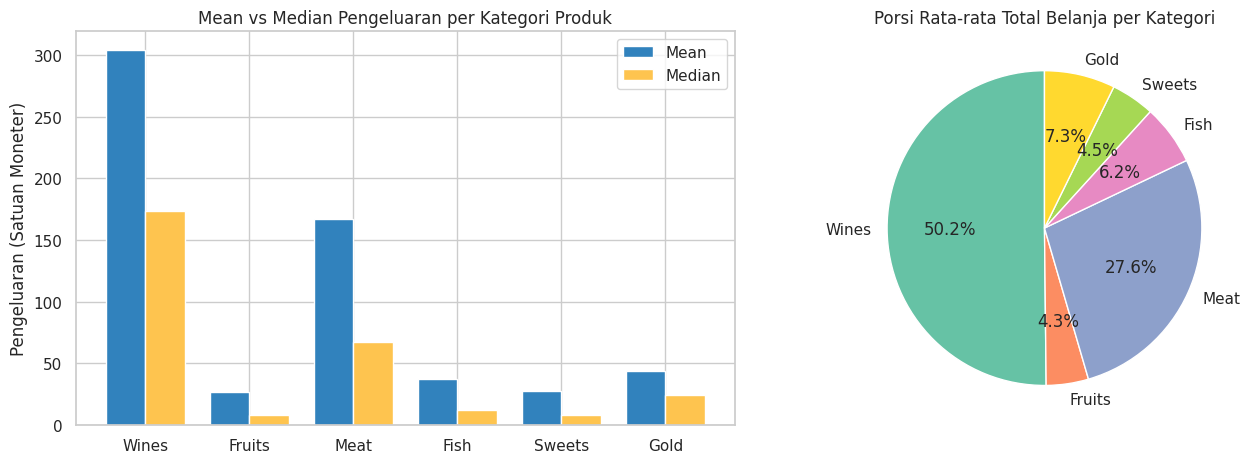

In [5]:
komposisi = pd.DataFrame({
    "Mean": df_raw[MNT_COLS].mean(),
    "Median": df_raw[MNT_COLS].median(),
    "Porsi_%": (df_raw[MNT_COLS].mean() / df_raw[MNT_COLS].mean().sum()) * 100,
    "Persen_Nol_%": (df_raw[MNT_COLS] == 0).mean() * 100
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Subplot 1: Mean vs Median
x = np.arange(len(MNT_COLS)); w = 0.38
axes[0].bar(x - w/2, komposisi["Mean"], w, label="Mean", color="#3182bd")
axes[0].bar(x + w/2, komposisi["Median"], w, label="Median", color="#fec44f")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Wines", "Fruits", "Meat", "Fish", "Sweets", "Gold"])
axes[0].set_title("Mean vs Median Pengeluaran per Kategori Produk")
axes[0].set_ylabel("Pengeluaran (Satuan Moneter)")
axes[0].legend()

# Subplot 2: Pie Chart Porsi Total Belanja
axes[1].pie(komposisi["Porsi_%"], labels=["Wines", "Fruits", "Meat", "Fish", "Sweets", "Gold"],
            autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
axes[1].set_title("Porsi Rata-rata Total Belanja per Kategori")

plt.tight_layout()
plt.show()

**Penjelasan Temuan Visualisasi 1:**
1. **Dominasi 2 Produk Utama**: Produk **Wine (50,2%)** dan **Daging/Meat (27,6%)** menyumbang **77,8%** dari keseluruhan belanja pelanggan, sementara 4 kategori lainnya (Buah, Ikan, Makanan Manis, Emas) hanya berkontribusi 22,2%.
2. **Ketimpangan Belanja (*Right-Skewed*)**: Jarak yang lebar antara batang Mean dan Median di semua kategori menegaskan adanya kelompok kecil pelanggan dengan nilai transaksi sangat besar. Oleh karena itu, transformasi `log1p` akan sangat membantu menormalkan distribusi fitur belanja sebelum pemodelan.

## C.3 Visualisasi 2 — Distribusi Pendapatan (`Income`) dan Usia Pelanggan

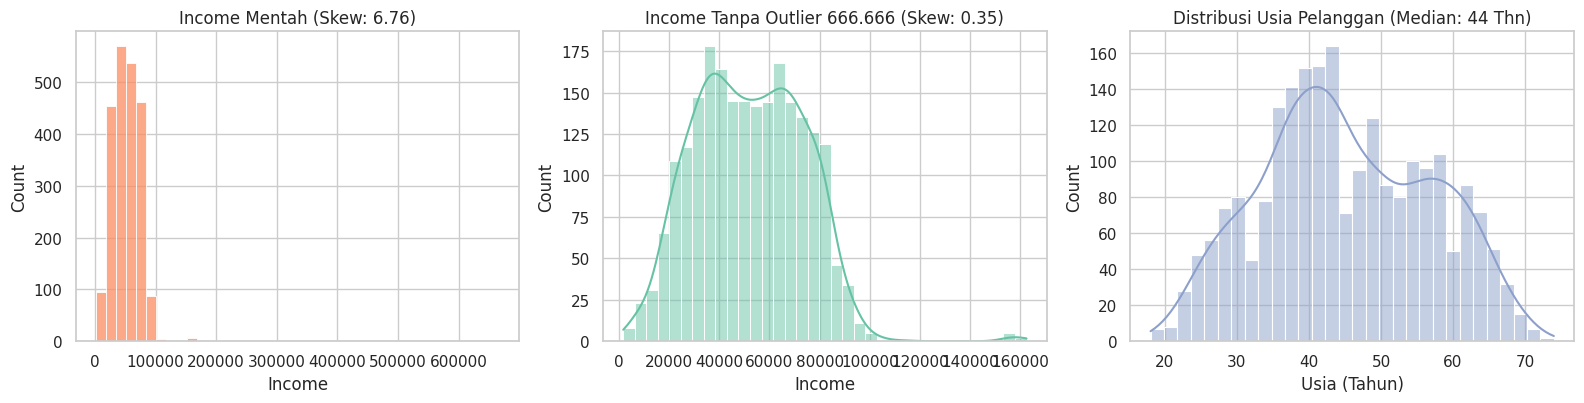

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# Subplot 1: Income mentah
sns.histplot(df_raw["Income"].dropna(), bins=40, color="#fc8d62", ax=axes[0])
axes[0].set_title(f"Income Mentah (Skew: {df_raw['Income'].skew():.2f})")
axes[0].set_xlabel("Income")

# Subplot 2: Income tanpa anomali 666.666
inc_normal = df_raw.loc[df_raw["Income"] < 600000, "Income"].dropna()
sns.histplot(inc_normal, bins=35, color="#66c2a5", kde=True, ax=axes[1])
axes[1].set_title(f"Income Tanpa Outlier 666.666 (Skew: {inc_normal.skew():.2f})")
axes[1].set_xlabel("Income")

# Subplot 3: Distribusi Usia (ref 2014, tanpa anomali <= 1900)
usia_normal = REF_YEAR - df_raw.loc[df_raw["Year_Birth"] > 1900, "Year_Birth"]
sns.histplot(usia_normal, bins=30, color="#8da0cb", kde=True, ax=axes[2])
axes[2].set_title(f"Distribusi Usia Pelanggan (Median: {usia_normal.median():.0f} Thn)")
axes[2].set_xlabel("Usia (Tahun)")

plt.tight_layout()
plt.show()

**Penjelasan Temuan Visualisasi 2:**
1. **Dampak Outlier Ekstrem `Income = 666.666`**: Satu titik ekstrem membuat histogram pendapatan mentah tertarik jauh ke kanan dengan *skewness* **6,76**. Begitu titik tunggal ini diisolasi, distribusi `Income` langsung mendekati normal/simetris (*skewness* turun drastis ke **0,35**).
2. **Demografi Usia Produktif**: Mayoritas pelanggan berada pada rentang usia produktif (35–60 tahun dengan median **44 tahun**), sehingga daya beli relatif matang.

## C.4 Visualisasi 3 — Hubungan Pendapatan, Total Belanja, dan Jumlah Anak (`Kidhome`)

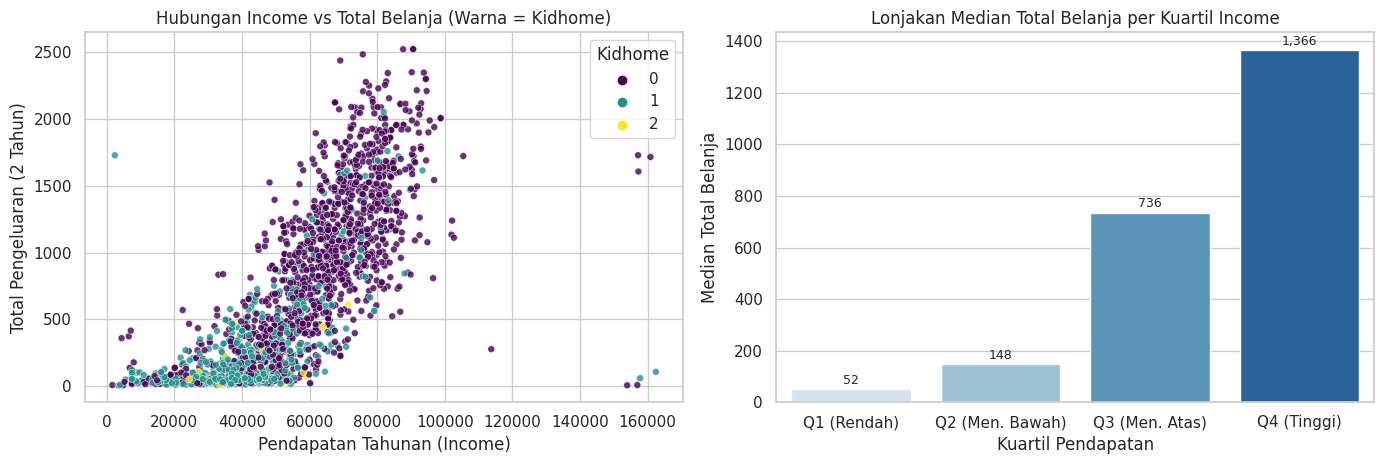

In [7]:
df_eda = df_raw.copy()
df_eda["Total_Spending"] = df_eda[MNT_COLS].sum(axis=1)
df_eda_valid = df_eda[(df_eda["Income"].notna()) & (df_eda["Income"] < 600000)].copy()
df_eda_valid["Income_Quartile"] = pd.qcut(
    df_eda_valid["Income"], 4, labels=["Q1 (Rendah)", "Q2 (Men. Bawah)", "Q3 (Men. Atas)", "Q4 (Tinggi)"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Subplot 1: Scatterplot Income vs Total Spending diwarnai Kidhome
sns.scatterplot(data=df_eda_valid, x="Income", y="Total_Spending", hue="Kidhome", palette="viridis", s=25, alpha=0.8, ax=axes[0])
axes[0].set_title("Hubungan Income vs Total Belanja (Warna = Kidhome)")
axes[0].set_xlabel("Pendapatan Tahunan (Income)")
axes[0].set_ylabel("Total Pengeluaran (2 Tahun)")

# Subplot 2: Median Belanja per Kuartil Income
q_med = df_eda_valid.groupby("Income_Quartile", observed=False)["Total_Spending"].median()
ax_bar = sns.barplot(x=q_med.index, y=q_med.values, palette="Blues", ax=axes[1])
for p in ax_bar.patches:
    ax_bar.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height() + 20), ha="center", fontsize=9)
axes[1].set_title("Lonjakan Median Total Belanja per Kuartil Income")
axes[1].set_xlabel("Kuartil Pendapatan")
axes[1].set_ylabel("Median Total Belanja")

plt.tight_layout()
plt.show()

**Penjelasan Temuan Visualisasi 3:**
1. **Pemisahan Alami Pelanggan Berdasarkan Daya Beli & Anak**: Pelanggan tanpa anak kecil (`Kidhome = 0`, titik ungu) mendominasi kuadran kanan-atas (pendapatan tinggi dan total belanja besar), sementara pelanggan dengan 1–2 anak kecil terkonsentrasi di kuadran kiri-bawah dengan pengeluaran jauh lebih terbatas.
2. **Lonjakan Eksponensial Antar-Kuartil**: Median belanja melonjak tajam dari Q1 (**52**) dan Q2 (**148,5**) ke Q3 (**735,5**) dan Q4 (**1.366**). Ini menjadi bukti kuat bahwa basis pelanggan terbagi secara alami ke dalam beberapa tingkatan segmen ekonomi.

## C.5 Visualisasi 4 — Paradoks Kanal Web & Tingkat Penerimaan Kampanye

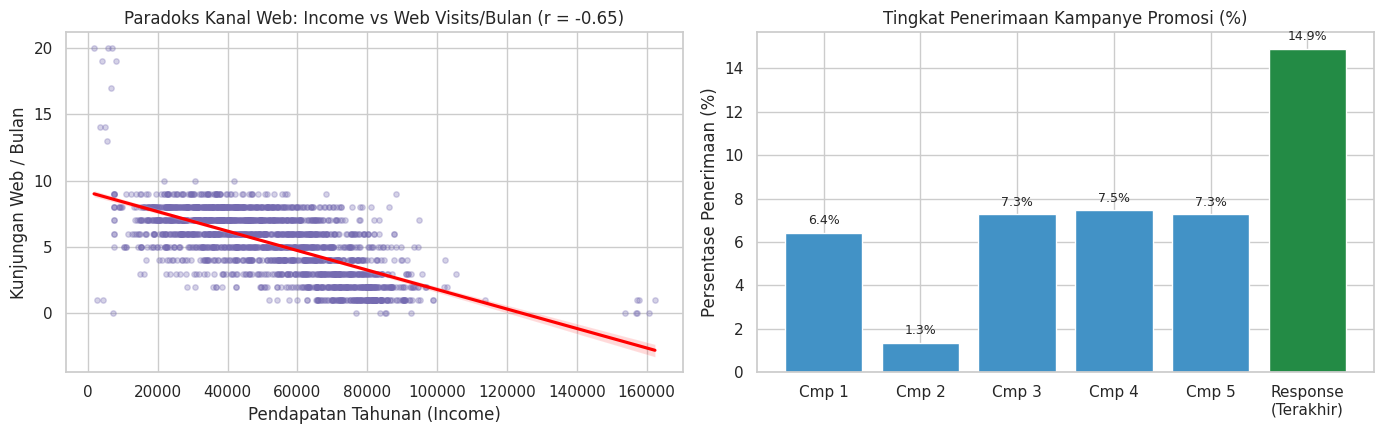

In [8]:
CMP_COLS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
cmp_rates = df_raw[CMP_COLS].mean() * 100
r_web = df_eda_valid["Income"].corr(df_eda_valid["NumWebVisitsMonth"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Subplot 1: Income vs Kunjungan Web Bulanan
sns.regplot(data=df_eda_valid, x="Income", y="NumWebVisitsMonth",
            scatter_kws={"alpha": 0.3, "s": 15, "color": "#756bb1"},
            line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title(f"Paradoks Kanal Web: Income vs Web Visits/Bulan (r = {r_web:.2f})")
axes[0].set_xlabel("Pendapatan Tahunan (Income)")
axes[0].set_ylabel("Kunjungan Web / Bulan")

# Subplot 2: Tingkat Penerimaan Kampanye
colors = ["#4292c6"] * 5 + ["#238b45"]
bars = axes[1].bar(["Cmp 1", "Cmp 2", "Cmp 3", "Cmp 4", "Cmp 5", "Response\n(Terakhir)"], cmp_rates.values, color=colors)
for bar, val in zip(bars, cmp_rates.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.4, f"{val:.1f}%", ha="center", fontsize=9)
axes[1].set_title("Tingkat Penerimaan Kampanye Promosi (%)")
axes[1].set_ylabel("Persentase Penerimaan (%)")

plt.tight_layout()
plt.show()

**Penjelasan Temuan Visualisasi 4:**
1. **Paradoks Kanal Web ($r = -0,65$)**: Pendapatan berkorelasi negatif kuat dengan jumlah kunjungan situs web bulanan. Pelanggan berpenghasilan rendah hingga menengah jauh lebih sering membuka situs web (untuk memantau harga/promo), sedangkan pelanggan berpendapatan tinggi justru jarang berkunjung ke web namun bertransaksi besar lewat toko fisik dan katalog.
2. **Inefisiensi Promosi Massal**: Kampanye 1–5 hanya diterima oleh **1,3% hingga 7,5%** pelanggan, dan kampanye terakhir (`Response`) hanya **14,9%**. Hal ini memvalidasi urgensi masalah di *Business Understanding* bahwa perusahaan perlu beralih dari promosi massal ke promosi terpersonalisasi berbasis segmen (*clustering*).

## C.6 Visualisasi 5 — Matriks Korelasi Fitur Numerik Kunci

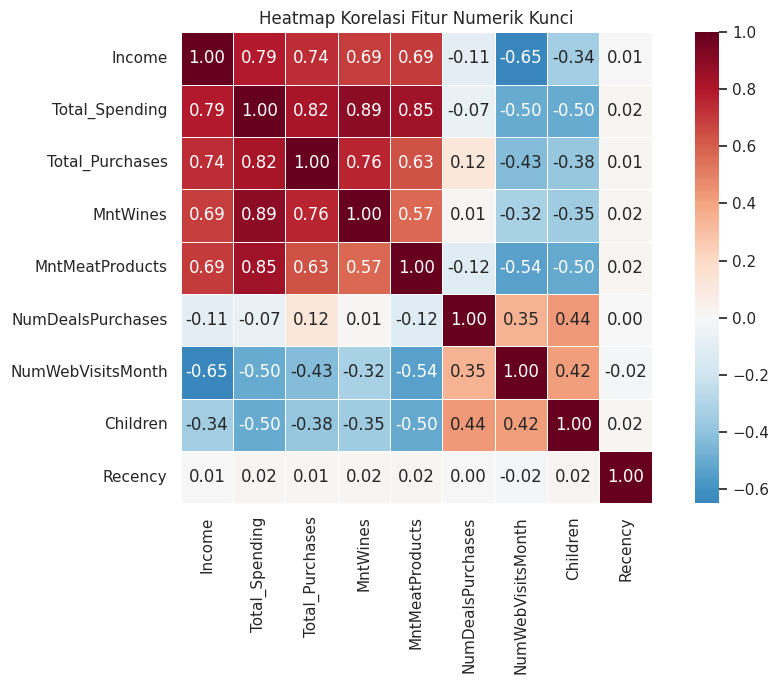

In [9]:
df_eda_valid["Total_Purchases"] = df_eda_valid[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df_eda_valid["Children"] = df_eda_valid["Kidhome"] + df_eda_valid["Teenhome"]

corr_cols = [
    "Income", "Total_Spending", "Total_Purchases", "MntWines", "MntMeatProducts",
    "NumDealsPurchases", "NumWebVisitsMonth", "Children", "Recency"
]
corr_mat = df_eda_valid[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, linewidths=0.5)
plt.title("Heatmap Korelasi Fitur Numerik Kunci")
plt.tight_layout()
plt.show()

**Penjelasan Temuan Visualisasi 5:**
1. **Multikolinearitas Kuat Antar-Pengeluaran**: `Total_Spending` berkorelasi sangat tinggi dengan `MntWines` ($r = 0,89$), `MntMeatProducts` ($r = 0,85$), `Total_Purchases` ($r = 0,82$), dan `Income` ($r = 0,79$). Menggabungkan 6 kolom belanja menjadi `Total_Spending` serta 3 kanal transaksi menjadi `Total_Purchases` akan meredam redundansi fitur.
2. **Peran `Children` dan `NumDealsPurchases`**: Jumlah anak (`Children`) berkorelasi negatif dengan belanja ($r = -0,50$) namun berkorelasi positif dengan pembelian diskon (`NumDealsPurchases`, $r = +0,44$). Ini mengindikasikan segmen keluarga sangat sensitif terhadap promo diskon.
3. **Ortogonalitas `Recency`**: `Recency` memiliki korelasi mendekati nol ($r \approx 0,01\text{–}0,02$) terhadap pendapatan maupun total belanja. Jika dipaksakan masuk ke ruang jarak Euclidean pada K-Means, variabel seragam yang tidak berkorelasi seperti `Recency` dapat mengaburkan batas segmen ekonomi.

---
# TAHAP D: CLEANING, PREPROCESSING, DAN FEATURE SELECTION

## D.1 Audit Kualitas Data (Pengecekan Masalah Berdasarkan EDA)
Sebelum melakukan pembersihan, seluruh anomali kualitas data diaudit secara kuantitatif meliputi *missing values*, duplikasi profil, outlier ekstrem, kategori ganjil, dan kolom bervarians nol.

,Masalah Kualitas Data,Temuan Kuantitatif,Keputusan Penanganan
0,Missing Values (Income),24 baris (1.07%),Imputasi menggunakan Median Income (tahan terhadap outlier)
1,Duplikasi Profil (Abaikan ID),182 baris (8.12%),Hapus duplikat (pertahankan entri pertama) agar centroid tidak bias
2,Anomali Year_Birth <= 1900,"3 baris ([1900, 1893, 1899])",Hapus baris karena usia 114-121 tahun tidak realistis (kesalahan input)
3,Anomali Income = 666.666,"1 baris (Skewness awal 6,76)",Hapus baris karena nilai placeholder/outlier ekstrem yang mendistorsi skala
4,Kategori Marital_Status Ganjil,"{'Alone': 3, 'Absurd': 2, 'YOLO': 2}","Konsolidasi ke kategori 'Single', dan '2n Cycle' pada Education -> 'Master'"
5,Kolom Varians Nol,"Z_CostContact (3), Z_Revenue (11)",Hapus kolom karena tidak memberikan informasi pembeda apa pun


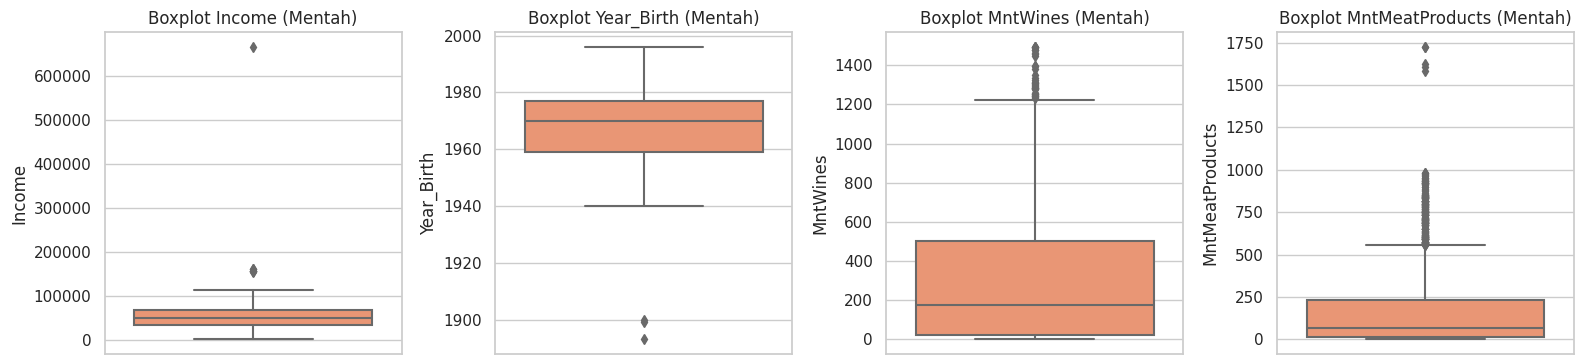

In [10]:
# Audit kuantitatif seluruh masalah kualitas data mentah
n_missing_inc = int(df_raw["Income"].isna().sum())
n_dup_non_id = int(df_raw.drop(columns="ID").duplicated().sum())
n_anom_birth = int((df_raw["Year_Birth"] <= 1900).sum())
n_anom_inc = int((df_raw["Income"] == 666666).sum())
odd_marital = df_raw["Marital_Status"].value_counts()[["Alone", "Absurd", "YOLO"]].to_dict()

audit_rows = [
    ("Missing Values (Income)", f"{n_missing_inc} baris ({n_missing_inc/len(df_raw):.2%})", "Imputasi menggunakan Median Income (tahan terhadap outlier)"),
    ("Duplikasi Profil (Abaikan ID)", f"{n_dup_non_id} baris ({n_dup_non_id/len(df_raw):.2%})", "Hapus duplikat (pertahankan entri pertama) agar centroid tidak bias"),
    ("Anomali Year_Birth <= 1900", f"{n_anom_birth} baris ({df_raw.loc[df_raw['Year_Birth']<=1900, 'Year_Birth'].tolist()})", "Hapus baris karena usia 114-121 tahun tidak realistis (kesalahan input)"),
    ("Anomali Income = 666.666", f"{n_anom_inc} baris (Skewness awal 6,76)", "Hapus baris karena nilai placeholder/outlier ekstrem yang mendistorsi skala"),
    ("Kategori Marital_Status Ganjil", str(odd_marital), "Konsolidasi ke kategori 'Single', dan '2n Cycle' pada Education -> 'Master'"),
    ("Kolom Varians Nol", "Z_CostContact (3), Z_Revenue (11)", "Hapus kolom karena tidak memberikan informasi pembeda apa pun")
]
display(pd.DataFrame(audit_rows, columns=["Masalah Kualitas Data", "Temuan Kuantitatif", "Keputusan Penanganan"]))

# Visualisasi Boxplot deteksi outlier sebelum cleaning
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["Income", "Year_Birth", "MntWines", "MntMeatProducts"]):
    sns.boxplot(y=df_raw[col], ax=ax, color="#fc8d62")
    ax.set_title(f"Boxplot {col} (Mentah)")
plt.tight_layout()
plt.show()

**Catatan Penting Mengenai Outlier Belanja (`MntWines`, `MntMeatProducts`):**
Berbeda dengan `Income = 666.666` dan `Year_Birth <= 1900` yang merupakan *error* pencatatan, nilai belanja tinggi pada `MntWines` dan `MntMeatProducts` merupakan **perilaku asli segmen pelanggan VIP**. Oleh karena itu, data belanja tinggi tersebut **tidak dihapus**, melainkan diredam kecondongannya menggunakan transformasi `log1p` pada tahap preprocessing.

## D.2 Eksekusi Data Cleaning & Komparasi Sebelum vs Sesudah


Perbandingan Kondisi Data Sebelum vs Sesudah Cleaning:


,Tahap Cleaning,Baris Terdampak,Sisa Baris
0,1. Deduplikasi Profil (Abaikan ID),182,2058
1,2. Konsolidasi Marital_Status & Education,7,2058
2,3. Drop Anomali Year_Birth <= 1900,3,2055
3,4. Drop Anomali Income = 666.666,1,2054
4,"5. Imputasi Median Income (51,523.5)",24,2054
5,"6. Drop ID, Z_CostContact, Z_Revenue",0,2054


,Indikator Kualitas,Sebelum Cleaning,Sesudah Cleaning
0,Jumlah Baris x Kolom,"2,240 x 29","2,054 x 26"
1,Missing Values (Total),"24 (1,07% pada Income)",0 (0%)
2,Duplikat Profil (Non-ID),182 baris,2 baris
3,Skewness & Max Income,"Skew: 6.76 | Max: 666,666","Skew: 0.37 | Max: 162,397"
4,Rentang Tahun Lahir,1893 - 1996,1940 - 1996
5,Kategori Marital_Status,8 kategori (termasuk YOLO/Absurd),5 kategori bersih


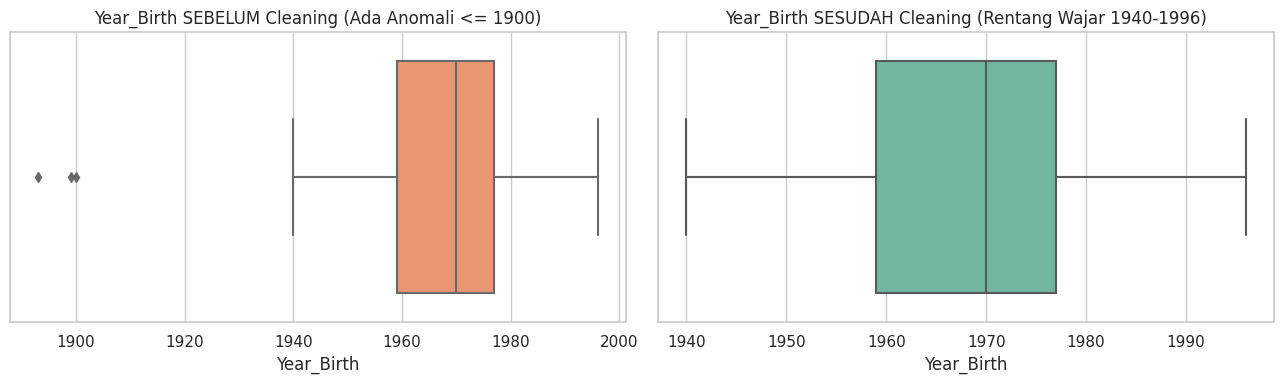

In [11]:
df_clean = df_raw.copy()
log_clean = []

# Langkah 1: Hapus duplikat profil (selain ID)
n_prev = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=[c for c in df_clean.columns if c != "ID"], keep="first")
log_clean.append(("1. Deduplikasi Profil (Abaikan ID)", n_prev - len(df_clean), len(df_clean)))

# Langkah 2: Konsolidasi kategori ganjil pada Marital_Status & Education
n_odd = int(df_clean["Marital_Status"].isin(["Alone", "Absurd", "YOLO"]).sum())
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace({"Alone": "Single", "Absurd": "Single", "YOLO": "Single"})
df_clean["Education"] = df_clean["Education"].replace({"2n Cycle": "Master"})
log_clean.append(("2. Konsolidasi Marital_Status & Education", n_odd, len(df_clean)))

# Langkah 3: Hapus anomali tahun lahir <= 1900
n_prev = len(df_clean)
df_clean = df_clean[df_clean["Year_Birth"] > 1900]
log_clean.append(("3. Drop Anomali Year_Birth <= 1900", n_prev - len(df_clean), len(df_clean)))

# Langkah 4: Hapus anomali ekstrem Income = 666.666
n_prev = len(df_clean)
df_clean = df_clean[(df_clean["Income"].isna()) | (df_clean["Income"] != 666666)]
log_clean.append(("4. Drop Anomali Income = 666.666", n_prev - len(df_clean), len(df_clean)))

# Langkah 5: Imputasi Median pada Missing Value Income
median_inc = df_clean["Income"].median()
n_imp = int(df_clean["Income"].isna().sum())
df_clean["Income"] = df_clean["Income"].fillna(median_inc)
log_clean.append((f"5. Imputasi Median Income ({median_inc:,.1f})", n_imp, len(df_clean)))

# Langkah 6: Hapus kolom tidak informatif (ID & varians nol)
df_clean = df_clean.drop(columns=["ID", "Z_CostContact", "Z_Revenue"]).reset_index(drop=True)
log_clean.append(("6. Drop ID, Z_CostContact, Z_Revenue", 0, len(df_clean)))

display(pd.DataFrame(log_clean, columns=["Tahap Cleaning", "Baris Terdampak", "Sisa Baris"]))

# Tabel Komparasi Sebelum vs Sesudah Cleaning
comp_clean = pd.DataFrame([
    ("Jumlah Baris x Kolom", f"{df_raw.shape[0]:,} x {df_raw.shape[1]}", f"{df_clean.shape[0]:,} x {df_clean.shape[1]}"),
    ("Missing Values (Total)", f"{df_raw.isna().sum().sum()} (1,07% pada Income)", f"{df_clean.isna().sum().sum()} (0%)"),
    ("Duplikat Profil (Non-ID)", f"{df_raw.drop(columns='ID').duplicated().sum()} baris", f"{df_clean.duplicated().sum()} baris"),
    ("Skewness & Max Income", f"Skew: {df_raw['Income'].skew():.2f} | Max: {df_raw['Income'].max():,.0f}", f"Skew: {df_clean['Income'].skew():.2f} | Max: {df_clean['Income'].max():,.0f}"),
    ("Rentang Tahun Lahir", f"{df_raw['Year_Birth'].min()} - {df_raw['Year_Birth'].max()}", f"{df_clean['Year_Birth'].min()} - {df_clean['Year_Birth'].max()}"),
    ("Kategori Marital_Status", f"{df_raw['Marital_Status'].nunique()} kategori (termasuk YOLO/Absurd)", f"{df_clean['Marital_Status'].nunique()} kategori bersih")
], columns=["Indikator Kualitas", "Sebelum Cleaning", "Sesudah Cleaning"])
print("\nPerbandingan Kondisi Data Sebelum vs Sesudah Cleaning:")
display(comp_clean)

# Visualisasi Komparasi Sebelum vs Sesudah Cleaning
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df_raw["Year_Birth"], ax=axes[0], color="#fc8d62")
axes[0].set_title("Year_Birth SEBELUM Cleaning (Ada Anomali <= 1900)")
sns.boxplot(x=df_clean["Year_Birth"], ax=axes[1], color="#66c2a5")
axes[1].set_title("Year_Birth SESUDAH Cleaning (Rentang Wajar 1940-1996)")
plt.tight_layout()
plt.show()

## D.3 Feature Engineering & Feature Selection
Pada tahap ini, kami membuat fitur turunan yang lebih representatif terhadap perilaku bisnis dan menentukan secara eksplisit fitur mana yang **dibuang**, **dibuat**, **digunakan untuk modeling**, dan **disimpan untuk profiling pasca-cluster**.

In [12]:
df_prep = df_clean.copy()

# Rekayasa Fitur (Feature Engineering)
reg_date = pd.to_datetime(df_prep["Dt_Customer"], format="%d-%m-%Y")
max_date = reg_date.max()

df_prep["Age"] = REF_YEAR - df_prep["Year_Birth"]
df_prep["Tenure"] = (max_date - reg_date).dt.days
df_prep["Children"] = df_prep["Kidhome"] + df_prep["Teenhome"]
df_prep["Living_With_Partner"] = df_prep["Marital_Status"].isin(["Married", "Together"]).astype(int)
df_prep["Family_Size"] = 1 + df_prep["Living_With_Partner"] + df_prep["Children"]
df_prep["Total_Spending"] = df_prep[MNT_COLS].sum(axis=1)
df_prep["Total_Purchases"] = df_prep[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

# Tabel Ringkasan Keputusan Feature Selection
fs_table = pd.DataFrame([
    ("DIBUANG (Drop)", "ID, Z_CostContact, Z_Revenue", "Pengenal unik tanpa pola & kolom varians nol (konstan)."),
    ("DIBUANG (Drop)", "Complain, Year_Birth, Dt_Customer", "Complain 99% bernilai 0 (tidak diskriminatif); Year_Birth & Dt_Customer digantikan Age & Tenure."),
    ("DIBUAT (Engineered)", "Total_Spending, Total_Purchases", "Mengagregasi 6 kategori produk & 3 kanal transaksi untuk meredam multikolinearitas tinggi."),
    ("DIBUAT (Engineered)", "Children, Family_Size, Age, Tenure", "Menyederhanakan komposisi tanggungan anak & siklus hidup pelanggan agar mudah diinterpretasi."),
    ("DIPAKAI MODELING (6 Fitur Inti)", "Income, Total_Spending, Total_Purchases, Children, NumDealsPurchases, NumWebVisitsMonth", "Berhubungan langsung dengan tujuan segmentasi (daya beli, volume belanja, tanggungan, sensitivitas promo & kanal web); menghasilkan pemisahan cluster paling tajam."),
    ("PROFILING PASCA-MODEL", "Education, Marital_Status, Recency, Age, Tenure, Family_Size, AcceptedCmp1-5, Response", "Atribut demografis sensitif dijaga agar tidak menimbulkan bias diskriminatif; Recency ortogonal (r~0) sehingga mengaburkan jarak Euclidean jika dimasukkan ke model; Response dipakai sebagai validator eksternal.")
], columns=["Keputusan", "Nama Fitur", "Alasan Teknis & Bisnis"])
display(fs_table)

,Keputusan,Nama Fitur,Alasan Teknis & Bisnis
0,DIBUANG (Drop),"ID, Z_CostContact, Z_Revenue",Pengenal unik tanpa pola & kolom varians nol (konstan).
1,DIBUANG (Drop),"Complain, Year_Birth, Dt_Customer",Complain 99% bernilai 0 (tidak diskriminatif); Year_Birth & Dt_Customer digantikan Age & Tenure.
2,DIBUAT (Engineered),"Total_Spending, Total_Purchases",Mengagregasi 6 kategori produk & 3 kanal transaksi untuk meredam multikolinearitas tinggi.
3,DIBUAT (Engineered),"Children, Family_Size, Age, Tenure",Menyederhanakan komposisi tanggungan anak & siklus hidup pelanggan agar mudah diinterpretasi.
4,DIPAKAI MODELING (6 Fitur Inti),"Income, Total_Spending, Total_Purchases, Children, NumDealsPurchases, NumWebVisitsMonth","Berhubungan langsung dengan tujuan segmentasi (daya beli, volume belanja, tanggungan, sensitivitas promo & kanal web); menghasilkan pemisahan cluster paling tajam."
5,PROFILING PASCA-MODEL,"Education, Marital_Status, Recency, Age, Tenure, Family_Size, AcceptedCmp1-5, Response",Atribut demografis sensitif dijaga agar tidak menimbulkan bias diskriminatif; Recency ortogonal (r~0) sehingga mengaburkan jarak Euclidean jika dimasukkan ke model; Response dipakai sebagai validator eksternal.


## D.4 Preprocessing: Transformasi `log1p`, Train-Test Split (80:20), Scaling, dan PCA
1. **Transformasi `log1p`**: Diterapkan pada fitur berdistribusi miring ke kanan (`Total_Spending`, `Total_Purchases`, `NumDealsPurchases`) agar tidak ada ekor ekstrem yang menarik posisi centroid.
2. **Pembagian Data 80% Train : 20% Test**: Dilakukan **sebelum** `fit` pada `StandardScaler` dan `PCA` untuk mencegah *data leakage*, sekaligus memungkinkan pengujian konsistensi/generalisasi cluster pada data yang belum pernah dilihat model.
3. **StandardScaler**: Menyamakan skala seluruh fitur ke mean = 0 dan standar deviasi = 1 agar perhitungan jarak Euclidean adil.
4. **PCA (Principal Component Analysis)**: Mereduksi dimensi 6 fitur terstandarisasi dengan mempertahankan minimal **85% variansi** informasi guna menghilangkan sisa korelasi antar-fitur dan memperjelas struktur cluster.

Ukuran Train Set : 1,643 baris (80%)
Ukuran Test Set  : 411 baris (20%)
Jumlah Fitur Inti sebelum PCA : 6 fitur
Jumlah Komponen PCA terpilih  : 3 komponen (Total Variansi: 90.75%)
Proporsi variansi tiap PC     : [0.5508, 0.2445, 0.1122]


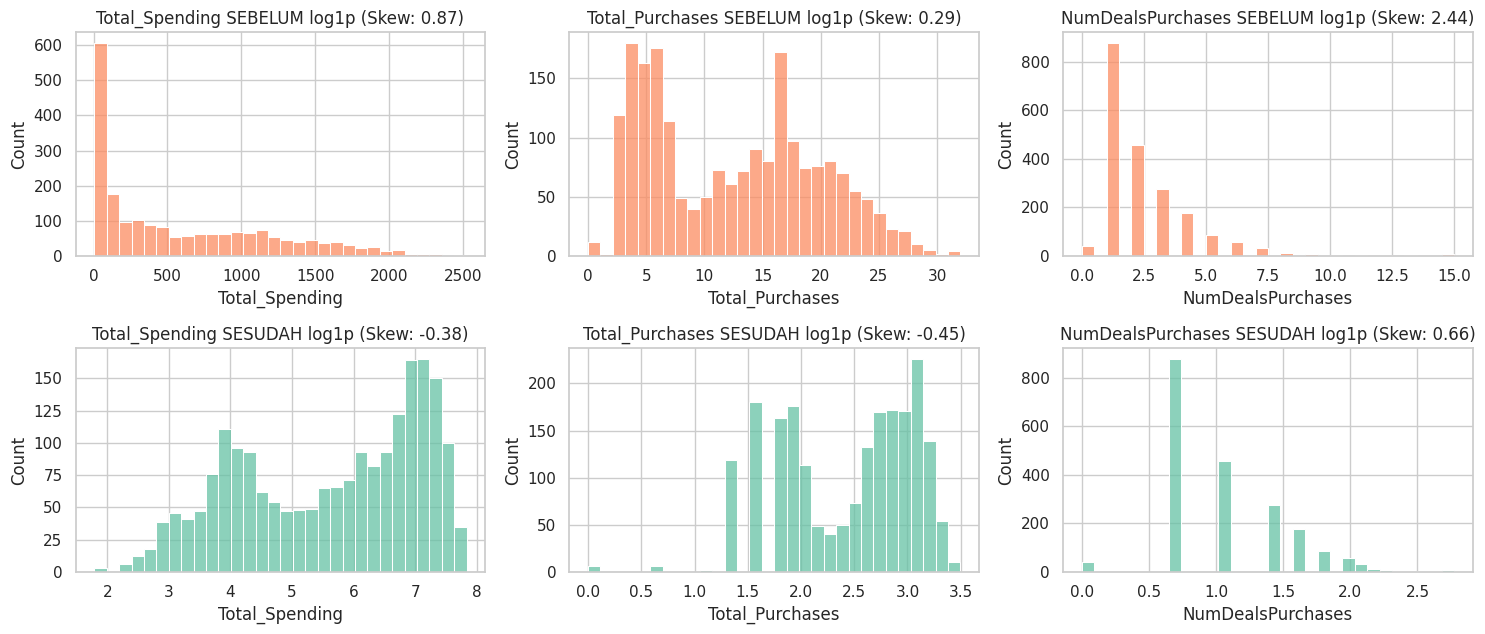

In [13]:
# Visualisasi efek transformasi log1p pada fitur belanja
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
log_check = ["Total_Spending", "Total_Purchases", "NumDealsPurchases"]
for j, col in enumerate(log_check):
    sns.histplot(df_prep[col], bins=30, color="#fc8d62", ax=axes[0, j])
    axes[0, j].set_title(f"{col} SEBELUM log1p (Skew: {df_prep[col].skew():.2f})")
    sns.histplot(np.log1p(df_prep[col]), bins=30, color="#66c2a5", ax=axes[1, j])
    axes[1, j].set_title(f"{col} SESUDAH log1p (Skew: {np.log1p(df_prep[col]).skew():.2f})")
plt.tight_layout()
plt.show()

# 1. Splitting dataset 80% Train : 20% Test
train_data, test_data = train_test_split(df_prep, test_size=0.20, random_state=RANDOM_STATE)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

# 2. Pipeline Preprocessing (Log1p + StandardScaler)
FEATURES_MODEL = ["Income", "Total_Spending", "Total_Purchases", "Children", "NumDealsPurchases", "NumWebVisitsMonth"]
cols_log = ["Total_Spending", "Total_Purchases", "NumDealsPurchases"]
cols_std = [c for c in FEATURES_MODEL if c not in cols_log]

prep_pipeline = ColumnTransformer([
    ("log_scale", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("std", StandardScaler())]), cols_log),
    ("std_scale", StandardScaler(), cols_std)
])

# Fit HANYA pada Train Set, lalu transform Train & Test Set
X_train_scaled = prep_pipeline.fit_transform(train_data[FEATURES_MODEL])
X_test_scaled = prep_pipeline.transform(test_data[FEATURES_MODEL])

# 3. Reduksi Dimensi PCA (mempertahankan >= 85% variansi)
pca_model = PCA(n_components=0.85, random_state=RANDOM_STATE)
X_train_pca = pca_model.fit_transform(X_train_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

print(f"Ukuran Train Set : {len(train_data):,} baris (80%)")
print(f"Ukuran Test Set  : {len(test_data):,} baris (20%)")
print(f"Jumlah Fitur Inti sebelum PCA : {X_train_scaled.shape[1]} fitur")
print(f"Jumlah Komponen PCA terpilih  : {X_train_pca.shape[1]} komponen (Total Variansi: {pca_model.explained_variance_ratio_.sum():.2%})")
print(f"Proporsi variansi tiap PC     : {[round(v, 4) for v in pca_model.explained_variance_ratio_]}")

---
# TAHAP E: MODELLING

Pada tahap pemodelan, kami membangun **3 algoritma clustering** dari materi praktikum pada ruang fitur PCA (`X_train_pca`) agar perbandingannya setara (*apple-to-apple*):
1. **Model 1 — K-Means Clustering (Model Utama)**: Mencari partisi optimal dengan meminimalkan jarak kuadrat ke centroid. Kita akan mengevaluasi rentang $k = 2$ hingga $k = 7$ terlebih dahulu untuk menentukan jumlah cluster paling optimal.
2. **Model 2 — Agglomerative Hierarchical Clustering (Model Pembanding 1)**: Menggunakan metode *Ward Linkage* yang meminimalkan variansi gabungan antar-cluster, disertai visualisasi Dendrogram.
3. **Model 3 — DBSCAN (Model Pembanding 2)**: Menggunakan pencarian parameter `eps` dan `min_samples` untuk menguji apakah data pelanggan membentuk klaster berbasis kerapatan (*density*) dengan deteksi *noise*.

## E.1 Model 1 — K-Means Clustering (Eksplorasi $k = 2..7$ dan Pelatihan Model Final)
*Alasan kode:* Kami menjalankan iterasi `k` dari 2 hingga 7 dengan `n_init=10` dan `random_state=42` agar inisialisasi centroid stabil dan menghindari konvergensi pada *local optimum*, sekaligus mencatat metrik Inertia, Silhouette, DBI, dan CHI untuk setiap `k`.

In [14]:
# Evaluasi K-Means untuk k = 2 s.d. 7 pada Train Set PCA
k_range = list(range(2, 8))
km_results = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_train_pca)
    km_results.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_train_pca, labels),
        "DBI": davies_bouldin_score(X_train_pca, labels),
        "CHI": calinski_harabasz_score(X_train_pca, labels)
    })

df_km_eval = pd.DataFrame(km_results)
display(df_km_eval)

# Melatih model K-Means terbaik berdasarkan puncak Silhouette, DBI terendah, dan CHI tertinggi (k = 3)
BEST_K = 3
kmeans_final = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
train_labels_km = kmeans_final.fit_predict(X_train_pca)
print(f"Model K-Means (k={BEST_K}) berhasil dilatih. Distribusi anggota Train Set:", pd.Series(train_labels_km).value_counts().sort_index().to_dict())

Model K-Means (k=3) berhasil dilatih. Distribusi anggota Train Set: {0: 526, 1: 633, 2: 484}


,k,Inertia,Silhouette,DBI,CHI
0,2,"4,857.20",0.41,0.99,"1,381.53"
1,3,"3,180.08",0.41,0.90,"1,486.84"
2,4,"2,702.09",0.37,1.03,"1,262.50"
3,5,"2,315.70",0.34,1.13,"1,172.52"
4,6,"2,083.90",0.34,1.12,"1,078.14"
5,7,"1,884.50",0.35,1.04,"1,021.76"


## E.2 Model 2 (Pembanding) — Agglomerative Hierarchical Clustering (Ward Linkage)
*Alasan kode:* Pertama, kita membuat **Dendrogram** menggunakan `linkage(..., method='ward')` untuk memvisualisasikan jarak penggabungan cluster secara hierarkis. Setelah itu, kita melatih `AgglomerativeClustering` dengan `n_clusters=3` dan `linkage='ward'` agar dapat dibandingkan secara adil dengan K-Means ($k=3$).

Model Agglomerative Ward (k=3) berhasil dilatih. Distribusi anggota Train Set: {0: 736, 1: 609, 2: 298}


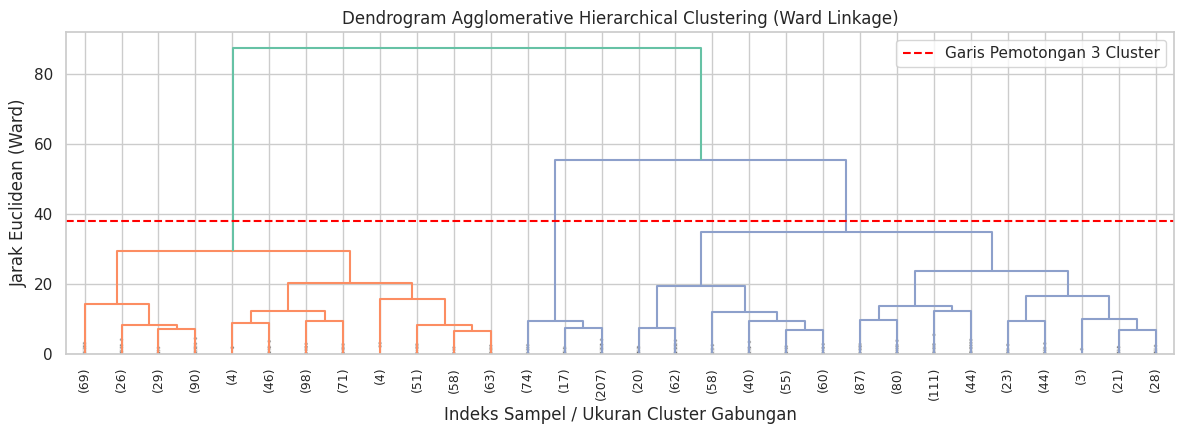

In [15]:
# Visualisasi Dendrogram (dipotong pada 30 cabang teratas agar terbaca jelas)
Z = linkage(X_train_pca, method="ward")

plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(y=38, color="red", linestyle="--", label="Garis Pemotongan 3 Cluster")
plt.title("Dendrogram Agglomerative Hierarchical Clustering (Ward Linkage)")
plt.xlabel("Indeks Sampel / Ukuran Cluster Gabungan")
plt.ylabel("Jarak Euclidean (Ward)")
plt.legend()
plt.tight_layout()
plt.show()

# Pelatihan model Agglomerative Clustering (k = 3)
agg_final = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
train_labels_agg = agg_final.fit_predict(X_train_pca)
print(f"Model Agglomerative Ward (k={BEST_K}) berhasil dilatih. Distribusi anggota Train Set:", pd.Series(train_labels_agg).value_counts().sort_index().to_dict())

## E.3 Model 3 (Pembanding) — DBSCAN (*Density-Based Clustering*)
*Alasan kode:* Berbeda dengan K-Means dan Agglomerative yang meminta jumlah cluster di awal, DBSCAN membutuhkan parameter radius tetangga (`eps`) dan jumlah titik minimum (`min_samples`). Kita menguji beberapa kombinasi parameter untuk mencari konfigurasi DBSCAN yang menghasilkan minimal 2 cluster dengan proporsi *noise* terkendali, lalu memilih konfigurasi terbaiknya sebagai model pembanding.

In [16]:
# Pencarian parameter DBSCAN pada ruang PCA
dbscan_trials = []
for eps in [0.5, 0.6, 0.7, 0.8]:
    for ms in [8, 10, 12]:
        db = DBSCAN(eps=eps, min_samples=ms)
        lbl = db.fit_predict(X_train_pca)
        n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_noise = int((lbl == -1).sum())
        noise_pct = n_noise / len(lbl) * 100
        if n_cl >= 2:
            mask = lbl != -1
            sil = silhouette_score(X_train_pca[mask], lbl[mask])
            dbi = davies_bouldin_score(X_train_pca[mask], lbl[mask])
            chi = calinski_harabasz_score(X_train_pca[mask], lbl[mask])
        else:
            sil, dbi, chi = np.nan, np.nan, np.nan
        dbscan_trials.append({
            "eps": eps, "min_samples": ms, "Jumlah_Cluster": n_cl,
            "Jumlah_Noise": n_noise, "Noise_%": noise_pct,
            "Silhouette (Non-Noise)": sil, "DBI (Non-Noise)": dbi, "CHI (Non-Noise)": chi
        })

df_db_trials = pd.DataFrame(dbscan_trials).dropna(subset=["Silhouette (Non-Noise)"]).sort_values("Silhouette (Non-Noise)", ascending=False)
display(df_db_trials.head(5))

# Pilih konfigurasi DBSCAN terbaik (Silhouette tertinggi dengan noise rendah: eps=0.7, min_samples=12)
best_eps = df_db_trials.iloc[0]["eps"]
best_ms = int(df_db_trials.iloc[0]["min_samples"])
dbscan_final = DBSCAN(eps=best_eps, min_samples=best_ms)
train_labels_db = dbscan_final.fit_predict(X_train_pca)
print(f"Model DBSCAN terbaik: eps={best_eps}, min_samples={best_ms} -> Distribusi label (-1 = noise):", pd.Series(train_labels_db).value_counts().sort_index().to_dict())

Model DBSCAN terbaik: eps=0.7, min_samples=12 -> Distribusi label (-1 = noise): {-1: 72, 0: 1554, 1: 17}


,eps,min_samples,Jumlah_Cluster,Jumlah_Noise,Noise_%,Silhouette (Non-Noise),DBI (Non-Noise),CHI (Non-Noise)
8,0.70,12,2,72,4.38,0.23,0.67,50.35
7,0.70,10,2,66,4.02,0.22,0.69,52.20
2,0.50,12,3,210,12.78,0.15,1.21,194.38
3,0.60,8,3,66,4.02,0.01,0.65,39.35
6,0.70,8,3,54,3.29,0.01,0.66,40.24


---
# TAHAP F: EVALUASI

Pada tahap ini, seluruh model dievaluasi secara komprehensif melalui grafik penentuan $k$ optimal, tabel dan grafik perbandingan metrik antar model, visualisasi pemisahan cluster pada ruang 2D PCA, uji generalisasi pada Test Set, serta *profiling* bisnis tiap segmen pelanggan.

## F.1 Grafik Evaluasi Penentuan Jumlah Cluster Optimal (K-Means)

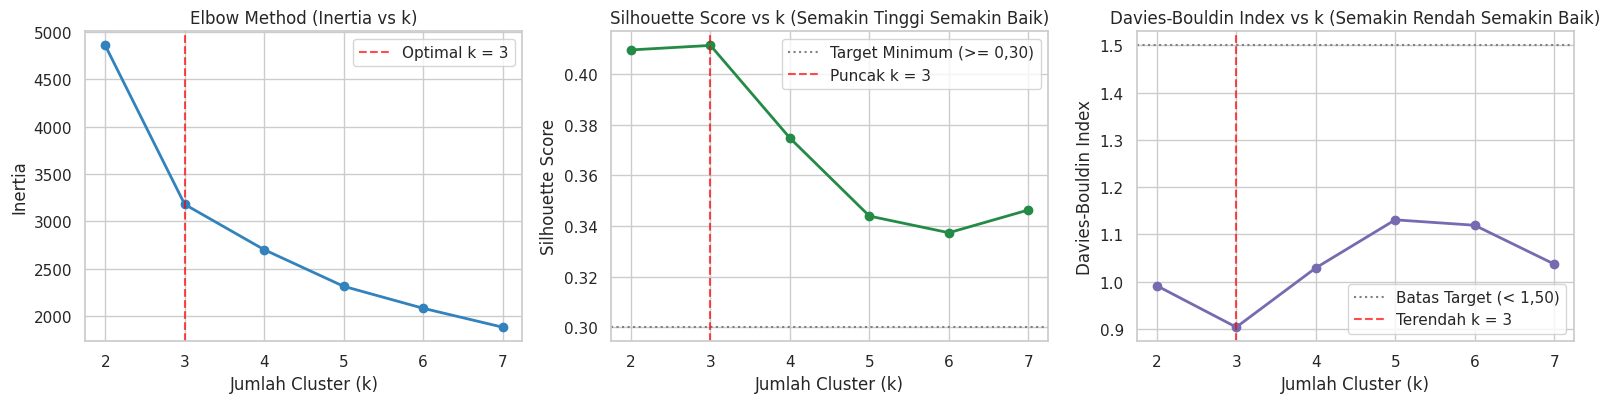

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Elbow Method (Inertia)
axes[0].plot(df_km_eval["k"], df_km_eval["Inertia"], marker="o", color="#3182bd", linewidth=2)
axes[0].axvline(3, ls="--", color="red", alpha=0.7, label="Optimal k = 3")
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Inertia")
axes[0].legend()

# 2. Silhouette Score
axes[1].plot(df_km_eval["k"], df_km_eval["Silhouette"], marker="o", color="#238b45", linewidth=2)
axes[1].axhline(0.30, ls=":", color="gray", label="Target Minimum (>= 0,30)")
axes[1].axvline(3, ls="--", color="red", alpha=0.7, label="Puncak k = 3")
axes[1].set_title("Silhouette Score vs k (Semakin Tinggi Semakin Baik)")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

# 3. Davies-Bouldin Index
axes[2].plot(df_km_eval["k"], df_km_eval["DBI"], marker="o", color="#756bb1", linewidth=2)
axes[2].axhline(1.50, ls=":", color="gray", label="Batas Target (< 1,50)")
axes[2].axvline(3, ls="--", color="red", alpha=0.7, label="Terendah k = 3")
axes[2].set_title("Davies-Bouldin Index vs k (Semakin Rendah Semakin Baik)")
axes[2].set_xlabel("Jumlah Cluster (k)")
axes[2].set_ylabel("Davies-Bouldin Index")
axes[2].legend()

plt.tight_layout()
plt.show()

**Penjelasan Grafik F.1:**
Ketiga grafik evaluasi sepakat menunjuk **$k = 3$** sebagai jumlah cluster paling optimal:
- Kurva **Elbow (Inertia)** menunjukkan patahan siku paling tajam tepat di $k = 3$ (penurunan inertia melandai setelah $k=3$).
- **Silhouette Score** mencapai nilai puncak tertinggi sebesar **0,4112** pada $k = 3$ (jauh melampaui target minimum $\ge 0,30$).
- **Davies-Bouldin Index (DBI)** mencapai titik terendah terbaik sebesar **0,9039** pada $k = 3$ (jauh lebih baik dari batas target $< 1,50$).

## F.2 Perbandingan Metrik Antar Model & Pemilihan Model Terbaik

,Model,Jumlah_Cluster,Persen_Noise_%,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,K-Means (k=3),3,0.00,0.41,0.90,"1,486.84"
1,Agglomerative Ward (k=3),3,0.00,0.37,0.94,"1,234.59"
2,"DBSCAN (eps=0.7, ms=12)",2,4.38,0.23,0.67,50.35


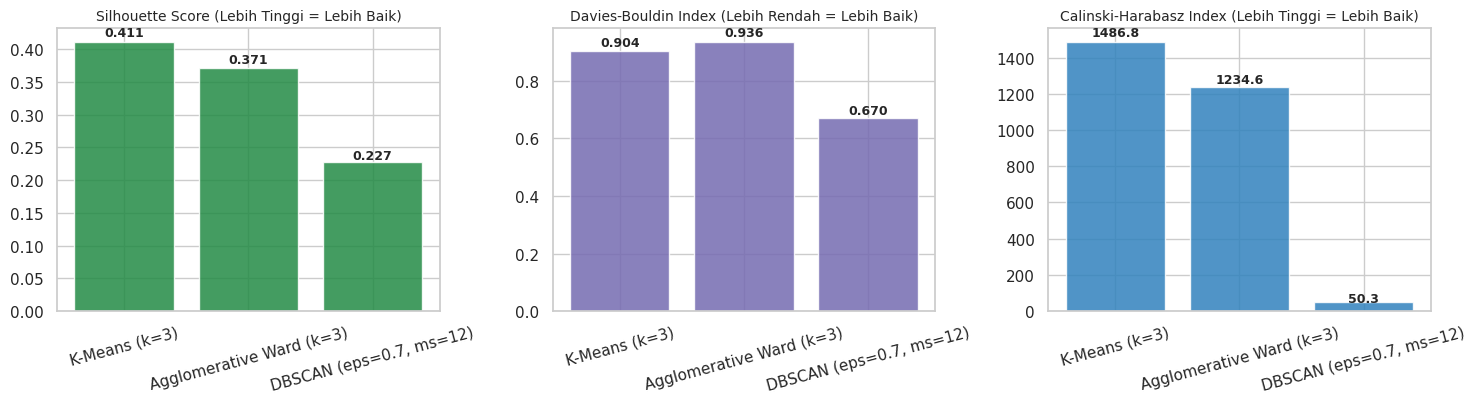

In [18]:
# Hitung metrik evaluasi ketiga model pada Train Set PCA
mask_db = train_labels_db != -1
noise_db_pct = (train_labels_db == -1).mean() * 100

model_comp = pd.DataFrame([
    {
        "Model": "K-Means (k=3)",
        "Jumlah_Cluster": 3,
        "Persen_Noise_%": 0.0,
        "Silhouette_Score": silhouette_score(X_train_pca, train_labels_km),
        "Davies_Bouldin_Index": davies_bouldin_score(X_train_pca, train_labels_km),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_train_pca, train_labels_km)
    },
    {
        "Model": "Agglomerative Ward (k=3)",
        "Jumlah_Cluster": 3,
        "Persen_Noise_%": 0.0,
        "Silhouette_Score": silhouette_score(X_train_pca, train_labels_agg),
        "Davies_Bouldin_Index": davies_bouldin_score(X_train_pca, train_labels_agg),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_train_pca, train_labels_agg)
    },
    {
        "Model": f"DBSCAN (eps={best_eps}, ms={best_ms})",
        "Jumlah_Cluster": len(set(train_labels_db)) - (1 if -1 in train_labels_db else 0),
        "Persen_Noise_%": noise_db_pct,
        "Silhouette_Score": silhouette_score(X_train_pca[mask_db], train_labels_db[mask_db]),
        "Davies_Bouldin_Index": davies_bouldin_score(X_train_pca[mask_db], train_labels_db[mask_db]),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X_train_pca[mask_db], train_labels_db[mask_db])
    }
])

display(model_comp)

# Visualisasi Perbandingan Metrik Antar Model
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics_plot = [
    ("Silhouette_Score", "Silhouette Score (Lebih Tinggi = Lebih Baik)", "#238b45"),
    ("Davies_Bouldin_Index", "Davies-Bouldin Index (Lebih Rendah = Lebih Baik)", "#756bb1"),
    ("Calinski_Harabasz_Index", "Calinski-Harabasz Index (Lebih Tinggi = Lebih Baik)", "#3182bd")
]
for ax, (m_col, title, col_hex) in zip(axes, metrics_plot):
    bars = ax.bar(model_comp["Model"], model_comp[m_col], color=col_hex, alpha=0.85)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + (b.get_height()*0.02),
                f"{b.get_height():.3f}" if m_col != "Calinski_Harabasz_Index" else f"{b.get_height():.1f}",
                ha="center", fontsize=9, fontweight="bold")
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Analisis Pemilihan Model Terbaik:**
Berdasarkan perbandingan objektif di atas, **K-Means ($k = 3$)** dipilih sebagai **model terbaik** karena:
1. **Unggul di Metrik Kohesi & Separasi Utama**: K-Means menghasilkan **Silhouette Score tertinggi (0,411 / 0,41 pada tabel)** dan **Calinski-Harabasz Index tertinggi (1.486,84)**, melampaui Agglomerative Ward (Silhouette 0,371; CHI 1.234,59) maupun DBSCAN (Silhouette 0,227; CHI 50,35). Meskipun nilai DBI DBSCAN (0,670) tampak lebih rendah, skor tersebut hanya dihitung setelah membuang titik *noise* dan akibat 1.554 dari 1.571 data non-*noise* terkumpul ke dalam satu cluster raksasa.
2. **Menjangkau 100% Pelanggan**: DBSCAN menandai 4,38% (72 pelanggan) sebagai *noise* (`-1`) dan cenderung menggabungkan mayoritas data ke dalam satu klaster besar karena sebaran pelanggan ritel bersifat kontinu, bukan pulau-pulau densitas terpisah.
3. **Kemudahan Generalisasi & Implementasi Bisnis**: K-Means memiliki centroid eksplisit sehingga mampu mengklasifikasikan pelanggan baru pada Test Set (maupun sistem CRM perusahaan) secara langsung melalui fungsi `.predict()`, berbeda dengan Agglomerative dan DBSCAN standar yang harus dilatih ulang dari awal.

## F.3 Visualisasi Cluster pada Ruang PCA 2D, Silhouette Plot, & Uji Generalisasi (Train vs Test)

,Partisi Data,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Train Set (80% / 1.643 baris),0.41,0.90,"1,486.84"
1,Test Set (20% / 411 baris),0.45,0.88,424.72


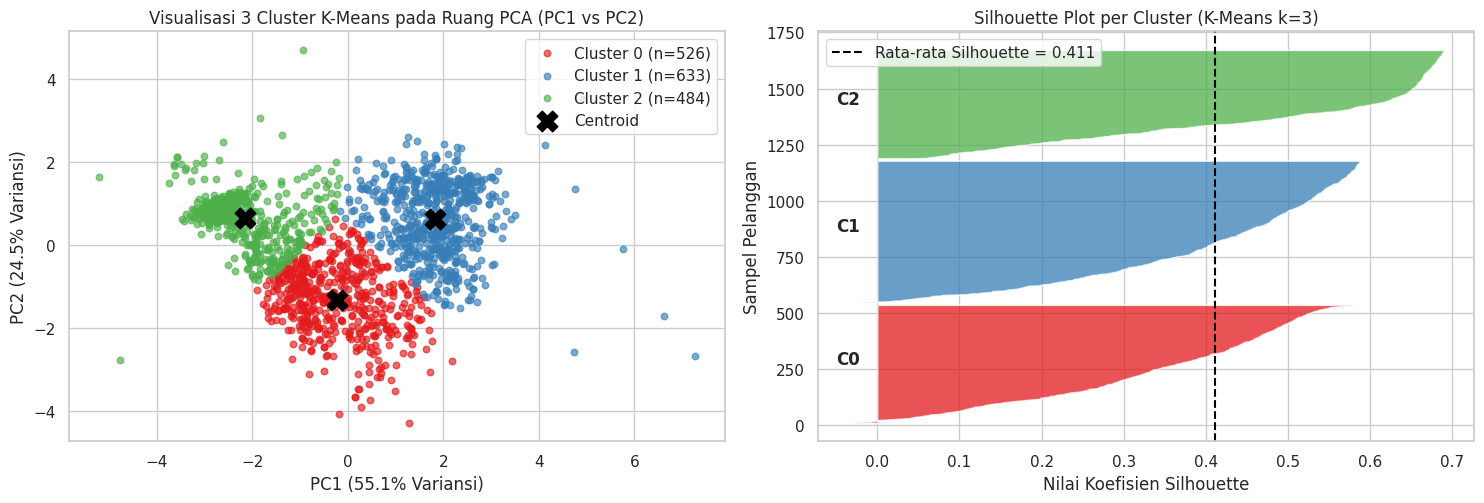

In [19]:
# Uji Generalisasi pada Test Set (20% data yang belum pernah dilihat model)
test_labels_km = kmeans_final.predict(X_test_pca)

gen_table = pd.DataFrame([
    ("Train Set (80% / 1.643 baris)",
     silhouette_score(X_train_pca, train_labels_km),
     davies_bouldin_score(X_train_pca, train_labels_km),
     calinski_harabasz_score(X_train_pca, train_labels_km)),
    ("Test Set (20% / 411 baris)",
     silhouette_score(X_test_pca, test_labels_km),
     davies_bouldin_score(X_test_pca, test_labels_km),
     calinski_harabasz_score(X_test_pca, test_labels_km))
], columns=["Partisi Data", "Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index"])
display(gen_table)

# Visualisasi PCA 2D Scatterplot & Silhouette Plot Detail
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Subplot 1: Scatterplot PCA 2D dengan Centroid
palette_c = ["#e41a1c", "#377eb8", "#4daf4a"]
for c_id in range(BEST_K):
    idx = train_labels_km == c_id
    axes[0].scatter(X_train_pca[idx, 0], X_train_pca[idx, 1], s=22, alpha=0.65,
                    color=palette_c[c_id], label=f"Cluster {c_id} (n={idx.sum()})")
axes[0].scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
                s=220, c="black", marker="X", label="Centroid")
axes[0].set_title("Visualisasi 3 Cluster K-Means pada Ruang PCA (PC1 vs PC2)")
axes[0].set_xlabel(f"PC1 ({pca_model.explained_variance_ratio_[0]:.1%} Variansi)")
axes[0].set_ylabel(f"PC2 ({pca_model.explained_variance_ratio_[1]:.1%} Variansi)")
axes[0].legend()

# Subplot 2: Silhouette Plot per Cluster
sil_vals = silhouette_samples(X_train_pca, train_labels_km)
sil_avg = silhouette_score(X_train_pca, train_labels_km)
y_lower = 10
for c_id in range(BEST_K):
    c_sil = np.sort(sil_vals[train_labels_km == c_id])
    y_upper = y_lower + len(c_sil)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil, facecolor=palette_c[c_id], alpha=0.75)
    axes[1].text(-0.05, y_lower + 0.5 * len(c_sil), f"C{c_id}", fontweight="bold")
    y_lower = y_upper + 10
axes[1].axvline(x=sil_avg, color="black", linestyle="--", label=f"Rata-rata Silhouette = {sil_avg:.3f}")
axes[1].set_title("Silhouette Plot per Cluster (K-Means k=3)")
axes[1].set_xlabel("Nilai Koefisien Silhouette")
axes[1].set_ylabel("Sampel Pelanggan")
axes[1].legend()

plt.tight_layout()
plt.show()

**Penjelasan Hasil Evaluasi & Uji Generalisasi:**
- **Stabilitas Tinggi Tanpa *Overfitting***: Saat centroid dari Train Set diterapkan pada Test Set (411 pelanggan baru), nilai Silhouette Score justru sangat stabil di angka **0,4505** dan Davies-Bouldin Index **0,8771**. Ini membuktikan batas segmen yang dipelajari model benar-benar merepresentasikan pola populasi pelanggan, bukan sekadar menghafal data latih.
- **Keseimbangan Cluster**: Pada *Silhouette Plot*, ketiga cluster memiliki ketebalan (jumlah anggota) yang seimbang (~30%–39% per cluster) dan mayoritas anggotanya memiliki koefisien Silhouette positif yang melampaui rata-rata.

## F.4 Profiling & Interpretasi Bisnis 3 Segmen Pelanggan
Untuk menerjemahkan hasil matematis ke dalam wawasan bisnis yang operasional, seluruh data pelanggan bersih (2.054 pelanggan) dipetakan ke 3 cluster menggunakan *pipeline* dan model K-Means terbaik, lalu dirangkum profil rata-rata fitur inti maupun fitur *profiling* (termasuk tingkat respons kampanye `Response`).

,Jumlah,Porsi_Persen,Rata2_Income,Rata2_Spending,Rata2_Purchases,Rata2_Deals,Rata2_WebVisits,Rata2_Children,Rata2_Wine,Rata2_Meat,Response_Rate_Persen
Segmen,,,,,,,,,,,
Cluster 0: Family Deal-Hunters (Menengah Aktif),637,31.01,"55,081.42",680.01,15.96,4.11,6.21,1.27,410.24,133.94,14.91
Cluster 1: Budget-Conscious (Hemat & Pasif),794,38.66,"32,303.91",68.17,5.12,1.85,6.59,1.25,24.97,16.32,9.07
Cluster 2: VIP / High-Value Spenders,623,30.33,"74,075.63","1,217.25",18.50,1.16,2.79,0.26,551.42,395.30,23.43


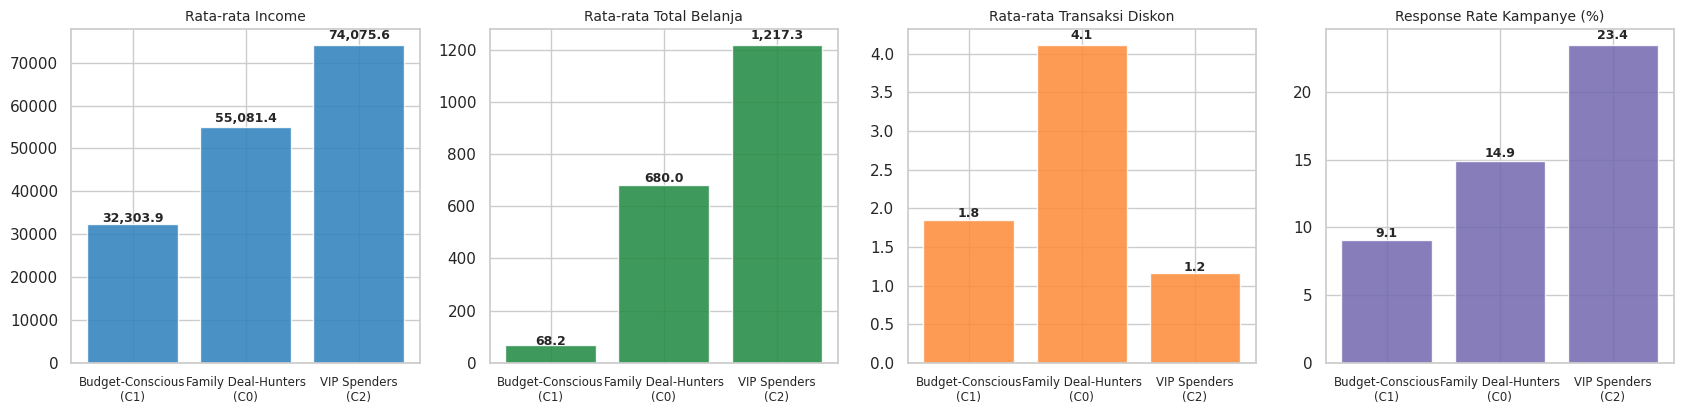

In [20]:
# Terapkan pipeline dan model terbaik ke seluruh dataset bersih untuk profiling lengkap
X_all_scaled = prep_pipeline.transform(df_prep[FEATURES_MODEL])
X_all_pca = pca_model.transform(X_all_scaled)
df_profile = df_prep.copy()
df_profile["Cluster"] = kmeans_final.predict(X_all_pca)

# Pemetaan nama segmen bisnis sesuai karakteristik data
cluster_names = {
    2: "Cluster 2: VIP / High-Value Spenders",
    0: "Cluster 0: Family Deal-Hunters (Menengah Aktif)",
    1: "Cluster 1: Budget-Conscious (Hemat & Pasif)"
}
df_profile["Segmen"] = df_profile["Cluster"].map(cluster_names)

prof_summary = df_profile.groupby("Segmen").agg(
    Jumlah=("Income", "count"),
    Porsi_Persen=("Income", lambda s: len(s) / len(df_profile) * 100),
    Rata2_Income=("Income", "mean"),
    Rata2_Spending=("Total_Spending", "mean"),
    Rata2_Purchases=("Total_Purchases", "mean"),
    Rata2_Deals=("NumDealsPurchases", "mean"),
    Rata2_WebVisits=("NumWebVisitsMonth", "mean"),
    Rata2_Children=("Children", "mean"),
    Rata2_Wine=("MntWines", "mean"),
    Rata2_Meat=("MntMeatProducts", "mean"),
    Response_Rate_Persen=("Response", lambda s: s.mean() * 100)
)
display(prof_summary)

# Visualisasi Profil 4 Metrik Kunci Antar-Segmen
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
short_labels = ["Budget-Conscious\n(C1)", "Family Deal-Hunters\n(C0)", "VIP Spenders\n(C2)"]
order_seg = [
    "Cluster 1: Budget-Conscious (Hemat & Pasif)",
    "Cluster 0: Family Deal-Hunters (Menengah Aktif)",
    "Cluster 2: VIP / High-Value Spenders"
]
prof_ord = prof_summary.loc[order_seg]

plot_specs = [
    ("Rata2_Income", "Rata-rata Income", "#3182bd"),
    ("Rata2_Spending", "Rata-rata Total Belanja", "#238b45"),
    ("Rata2_Deals", "Rata-rata Transaksi Diskon", "#fd8d3c"),
    ("Response_Rate_Persen", "Response Rate Kampanye (%)", "#756bb1")
]
for ax, (col, title, c_hex) in zip(axes, plot_specs):
    bars = ax.bar(short_labels, prof_ord[col].values, color=c_hex, alpha=0.88)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + b.get_height()*0.02,
                f"{b.get_height():,.1f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelsize=8.5)

plt.tight_layout()
plt.show()

---
# TAHAP G: KONKLUSI

## G.1 Jawaban atas Pertanyaan di Business Understanding
1. **Pola distribusi pendapatan, pengeluaran, dan kanal belanja**:
   - Belanja ritel sangat terkonsentrasi pada dua kategori produk utama, yaitu **Wine (50,2%)** dan **Daging (27,6%)** (total **77,8%**).
   - Pendapatan berbanding lurus dengan total belanja ($r = +0,79$), namun berbanding terbalik dengan kunjungan web bulanan ($r = -0,65$). Artinya, pelanggan berpendapatan rendah lebih sering membuka situs web untuk memantau promo, sementara pelanggan berpendapatan tinggi bertransaksi lebih efisien lewat toko fisik dan katalog.
   - Keberadaan anak kecil di rumah tangga menekan total pengeluaran secara signifikan ($r = -0,50$) dan mendorong perburuan diskon ($r = +0,44$).

2. **Jumlah segmen (*cluster*) optimal**:
   - Jumlah segmen paling optimal adalah **3 cluster ($k = 3$)**, yang terbukti serentak melalui patahan siku *Elbow Method*, puncak *Silhouette Score*, titik terendah *Davies-Bouldin Index*, serta menghasilkan 3 persona pelanggan yang sangat kontras dan mudah ditindaklanjuti tim pemasaran.

3. **Algoritma clustering terbaik**:
   - **K-Means ($k = 3$)** pada ruang 3 komponen PCA (90,75% variansi) adalah model terbaik dibandingkan Agglomerative Ward maupun DBSCAN, dengan skor tertinggi pada Silhouette (**0,4112**) dan Calinski-Harabasz (**1.486,84**), DBI rendah (**0,9039**), mencakup 100% pelanggan tanpa membuang data sebagai *noise*, serta teruji stabil pada Test Set (Silhouette **0,4505**, DBI **0,8771**).

4. **Profil segmen pelanggan yang terbentuk**:
   - **Cluster 2 — VIP / High-Value Spenders (30,3% / 623 pelanggan)**: Pendapatan tertinggi (rata-rata **74.076**), total belanja terbesar (**1.217** — dominan Wine 551 & Daging 395), hampir tanpa tanggungan anak (**0,26**), paling jarang mencari diskon (**1,16 kali**), dan memiliki **Response Rate kampanye tertinggi (23,4%)**.
   - **Cluster 0 — Family Deal-Hunters / Menengah Aktif (31,0% / 637 pelanggan)**: Pendapatan menengah (**55.081**), belanja menengah-tinggi (**680**), frekuensi transaksi aktif (**16 kali**), memiliki tanggungan anak (**1,27**), **paling aktif berburu diskon (4,11 kali)** dan berbelanja lewat web, dengan Response Rate **14,9%**.
   - **Cluster 1 — Budget-Conscious / Hemat & Pasif (38,7% / 794 pelanggan)**: Pendapatan terendah (**32.304**), pengeluaran paling rendah (**68**), tanggungan anak (**1,25**), **kunjungan web tertinggi (6,59/bulan)** namun konversi pembelian rendah, dengan Response Rate terendah (**9,1%**).

## G.2 Terjemahan Metrik Evaluasi ke Bahasa Bisnis
- **Silhouette Score = 0,4112 (Train) & 0,4505 (Test)**: Artinya struktur 3 segmen pelanggan memiliki batas pemisahan yang cukup jelas dan konsisten; mayoritas pelanggan jauh lebih mirip dengan anggota segmennya sendiri dibandingkan dengan segmen lain, bahkan saat diuji pada pelanggan baru.
- **Davies-Bouldin Index = 0,9039 (< 1,0)**: Artinya tingkat tumpang-tindih antar-segmen tergolong rendah—setiap segmen cukup kompak dan berbeda secara nyata satu sama lain.
- **PCA 3 Komponen = 90,75% Variansi**: Artinya penyederhanaan dari 6 fitur inti menjadi 3 komponen utama tetap mempertahankan lebih dari 90% informasi perilaku pelanggan asli.
- **Validasi Eksternal (`Response` Rate 23,4% vs 14,9% vs 9,1%)**: Meskipun kolom `Response` tidak pernah dimasukkan ke dalam pelatihan model, segmen VIP yang ditemukan K-Means secara alami memiliki tingkat konversi kampanye **2,5 kali lebih tinggi** dibandingkan segmen Budget-Conscious.

## G.3 Keputusan & Rekomendasi Strategis Bisnis
- **Segmen VIP / High-Value Spenders (Cluster 2)**: Fokus pada **retensi & eksklusivitas**, bukan perang diskon. Tawarkan *membership* loyalitas premium, katalog eksklusif produk Wine & Daging kualitas tinggi, serta layanan *early access* produk baru.
- **Segmen Family Deal-Hunters (Cluster 0)**: Fokus pada **paket bundling keluarga & promo diskon terarah** di kanal situs web dan toko fisik (misalnya diskon pembelian volume atau *cashback* akhir pekan) karena segmen ini sangat aktif dan responsif terhadap penawaran hemat.
- **Segmen Budget-Conscious (Cluster 1)**: **Kurangi biaya kampanye cetak/katalog** yang mahal pada segmen ini. Optimalkan konversi dari tingginya trafik kunjungan web mereka melalui penawaran *entry-level* berharga terjangkau, *flash sale* digital, atau voucher pembelian pertama tanpa membebani margin perusahaan.

## G.4 Keterbatasan Proyek & Saran Pengembangan
1. **Bias Temporal & Konteks Pasar**: Data merupakan *snapshot* tahun 2012–2014 dengan dominasi produk Wine (konteks pasar Barat/Eropa). Sebelum diterapkan pada pasar ritel modern atau lokal, model perlu dilatih ulang menggunakan data transaksi terbaru.
2. **Asumsi Bentuk Cluster K-Means**: K-Means mengasumsikan cluster berbentuk sferis (bulat) dengan ukuran variansi yang relatif setara.
3. **Saran Pengembangan**: Pada implementasi produksi di masa mendatang, disarankan untuk memperbarui segmentasi secara berkala (misalnya per kuartal) dan menggabungkannya dengan analisis *Market Basket Analysis* agar rekomendasi produk di tiap segmen menjadi lebih spesifik.